# Unión por segmentos de 50 m y buffers — Malla vial, puentes, peatonal, semáforos y siniestralidad

Este cuaderno reemplaza el enfoque de **fragmentos nativos + `sjoin_nearest`** por el enfoque
metodológico definitivo:

1. La **malla vial** recortada al perímetro POT se corta en **segmentos de ~50 m**.
2. Cada segmento genera un **buffer** (10, 15 y 20 m) que define su zona de influencia.
3. Toda la infraestructura (puentes, semáforos, malla peatonal) y toda la **siniestralidad peatonal**
   que cae dentro de ese buffer se **agrega al segmento**.
4. El resultado es una tabla a nivel de segmento: una fila = un tramo de ~50 m de vía, con sus
   atributos propios, su dotación de infraestructura y su **conteo de siniestros peatonales**,
   que es la variable objetivo de este cuaderno.

**Insumos requeridos** (generados por los cuadernos previos):

| Archivo | Origen |
|---|---|
| `Data/raw/perimetrourbano (1).gpkg` | POT Decreto 555 |
| `Data/processed/malla_vial_procesada.gpkg` | `EDA_Malla_Vial_Puentes_zona_urbana.ipynb` |
| `Data/processed/puentes_procesado.gpkg` | idem |
| `Data/processed/peatonal_procesada.gpkg` | `EDA_Malla_peatonal_semaforos.ipynb` |
| `Data/processed/semaforos_procesados.gpkg` | idem |
| `Data/processed/siniestros_procesados.gpkg` | `EDA2_Siniestros_Viales_Bogota_peatones...ipynb` (sección 9) |
| `anexo-proyecciones-poblacion-bogota-desagreacion-loc-2018-2035-UPZ-2018-2024.xlsx` | DANE / SDP — proyecciones de población por localidad, 2018-2035 |

Todo en **EPSG:3116** (MAGNA-SIRGAS / Bogotá), condición necesaria para que buffers y distancias
estén en metros reales.

**Nuevo en esta versión:**

- **Sección 5.7** — integración del anexo de proyecciones de población: cada siniestro se cruza con la población de su localidad en el año en que ocurrió, para calcular una tasa por 100.000 habitantes y no solo un conteo crudo.
- **Sección 9** — comparación de la granularidad de segmentación (**200 m, 50 m y 25 m**), con el radio de buffer fijo en 15 m, como análisis de sensibilidad al tamaño de segmento.


El cuaderno está organizado así:

1. Librerías y parámetros del diseño
2. Carga de insumos y estandarización de CRS
3. Segmentación de la malla vial en tramos de ~50 m
4. Zonas de influencia: buffers por segmento
5. Agregación de las capas a cada segmento
6. Construcción del dataset final por segmento
7. Vista espacial del resultado
8. Exportación
9. Comparación de granularidad de segmentación: 200 m, 50 m y 25 m
10. Resumen metodológico

## 1. Librerías y parámetros del diseño

In [1]:
import os
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.ops import substring
from shapely.geometry import LineString

pd.set_option('display.max_columns', 80)
plt.rcParams['figure.figsize'] = (9, 6)

# ---------------------------------------------------------------
# PARÁMETROS DEL DISEÑO METODOLÓGICO
# ---------------------------------------------------------------
CRS_PROYECTO = 3116          # MAGNA-SIRGAS / Colombia Bogotá zone (metros)
LONG_OBJETIVO = 50           # longitud objetivo del segmento, en metros
UMBRAL_RUIDO = 4             # descarta geometrías degeneradas de digitalización
BUFFERS = [10, 15, 20]       # radios de zona de influencia, en metros
BUFFER_PRINCIPAL = 15        # el que alimenta el dataset final; 10 y 20 = sensibilidad

DIR_PROC = 'Data/processed'
os.makedirs(DIR_PROC, exist_ok=True)

print(f"Segmentación objetivo: {LONG_OBJETIVO} m | Buffers: {BUFFERS} m "
      f"| Principal: {BUFFER_PRINCIPAL} m")

Segmentación objetivo: 50 m | Buffers: [10, 15, 20] m | Principal: 15 m


## 2. Carga de insumos y estandarización de CRS

Se fuerza el CRS de todas las capas a `EPSG:3116` en vez de asumirlo. Un CRS mal etiquetado
(grados tratados como metros) no falla de forma visible: produce buffers de 15 *grados* y
distancias sin sentido físico.

In [2]:
def cargar(ruta, nombre):
    gdf = gpd.read_file(ruta)
    if gdf.crs is None:
        raise ValueError(f"{nombre}: la capa no tiene CRS definido; no se puede asumir.")
    if gdf.crs.to_epsg() != CRS_PROYECTO:
        gdf = gdf.to_crs(epsg=CRS_PROYECTO)
    gdf = gdf[~gdf.geometry.isna() & ~gdf.geometry.is_empty].copy()
    return gdf

perimetro  = cargar("Data/raw/perimetrourbano (1).gpkg", 'perimetro')
malla      = cargar(f"{DIR_PROC}/malla_vial_procesada.gpkg", 'malla')
puentes    = cargar(f"{DIR_PROC}/puentes_procesado.gpkg", 'puentes')
peatonal   = cargar(f"{DIR_PROC}/peatonal_procesada.gpkg", 'peatonal')
semaforos  = cargar(f"{DIR_PROC}/semaforos_procesados.gpkg", 'semaforos')
siniestros = cargar(f"{DIR_PROC}/siniestros_procesados.gpkg", 'siniestros')

# El perímetro se reduce a una sola geometría disuelta: es una máscara, no una tabla.
perimetro = gpd.GeoDataFrame(geometry=[perimetro.union_all()], crs=perimetro.crs)

for nombre, capa in [('perimetro', perimetro), ('malla', malla), ('puentes', puentes),
                     ('peatonal', peatonal), ('semaforos', semaforos), ('siniestros', siniestros)]:
    print(f"{nombre:11s} -> {len(capa):>8,} filas | {capa.crs.to_epsg()} | "
          f"{sorted(capa.geom_type.unique())}")

DataSourceError: Data/raw/perimetrourbano (1).gpkg: No such file or directory

### 2.1 Recorte al perímetro urbano

Mismo criterio para todas las capas: lo que queda fuera del POT no entra al modelo. Se hace
antes de segmentar para no gastar cómputo cortando vías que después se descartan.

Los semáforos se filtran aparte por coordenadas imposibles (registros corruptos de fuente,
no error de CRS) — ese diagnóstico ya venía del cuaderno anterior.

In [ ]:
# Semáforos: exclusión de coordenadas físicamente imposibles (fuera de cualquier
# proyección válida para Bogotá). Se separa del clip porque es un problema de calidad
# de fuente, no de delimitación urbana.
minx, miny, maxx, maxy = perimetro.total_bounds
MARGEN = 5000
corruptos = semaforos[
    (semaforos.geometry.x < minx - MARGEN) | (semaforos.geometry.x > maxx + MARGEN) |
    (semaforos.geometry.y < miny - MARGEN) | (semaforos.geometry.y > maxy + MARGEN)
]
print(f"Semáforos con coordenada corrupta excluidos: {len(corruptos)} de {len(semaforos)}")
semaforos = semaforos.drop(index=corruptos.index).copy()

# Clip al POT de todas las capas
capas = {}
for nombre, capa in [('malla', malla), ('puentes', puentes), ('peatonal', peatonal),
                     ('semaforos', semaforos), ('siniestros', siniestros)]:
    antes = len(capa)
    recortada = gpd.clip(capa, perimetro)
    capas[nombre] = recortada
    print(f"{nombre:11s}: {antes:>8,} -> {len(recortada):>8,} "
          f"({len(recortada)/antes*100:5.1f}% conservado)")

malla, puentes, peatonal, semaforos, siniestros = (
    capas['malla'], capas['puentes'], capas['peatonal'],
    capas['semaforos'], capas['siniestros'])

Semáforos con coordenada corrupta excluidos: 1 de 1745
malla      :  136,956 ->  131,873 ( 96.3% conservado)
puentes    :    1,212 ->    1,068 ( 88.1% conservado)
peatonal   :   46,065 ->   45,964 ( 99.8% conservado)
semaforos  :    1,744 ->    1,733 ( 99.4% conservado)
siniestros :   21,893 ->   21,716 ( 99.2% conservado)


## 3. Segmentación de la malla vial en tramos de ~50 m

### 3.1 Criterio de corte

Cortar a 50 m exactos y dejar el sobrante como un tramo aparte produce **colas cortas**:
una vía de 105 m daría 50 + 50 + 5, y ese tramo de 5 m es una unidad de análisis inútil
(su buffer captura casi nada y su tasa de siniestros por metro se dispara).

Se usa en cambio **división en partes iguales con techo**: para una línea de longitud `L`,

```
n = max(1, ceil(L / 50))
```

y se corta en `n` tramos de `L/n` metros cada uno.

Detalle que importa: se usa `ceil`, no `round`. Con `round`, una vía de 70 m daría `n=1` y un
"segmento de 50 m" que en realidad mide 70 — el criterio permite tramos de hasta 75 m y, sobre
una distribución realista de longitudes de vía, solo ~52 % de los segmentos cae en el rango
40–50 m. Con `ceil`, **ningún tramo puede superar los 50 m** (esa misma vía de 70 m se parte en
dos de 35 m) y la proporción en rango sube a ~95 %. El costo es que la cota inferior baja hacia
25 m en el peor caso (`n=2` con `L` apenas por encima de 50).

Las líneas originalmente más cortas que 50 m se conservan enteras: son vías reales, no ruido, y
partirlas no tendría sentido. Son la única fuente de segmentos por debajo del rango objetivo.

In [ ]:
def segmentar_linea(linea, objetivo=LONG_OBJETIVO):
    """Divide una LineString en n partes iguales de longitud lo más cercana posible
    a `objetivo`. Devuelve lista de LineString. Nunca genera colas residuales."""
    L = linea.length
    if L <= 0:
        return []
    n = max(1, math.ceil(L / objetivo - 1e-9))
    if n == 1:
        return [linea]
    paso = L / n
    partes = []
    for i in range(n):
        tramo = substring(linea, i * paso, (i + 1) * paso)
        if isinstance(tramo, LineString) and tramo.length > 0:
            partes.append(tramo)
    return partes


def segmentar_capa(gdf, objetivo=LONG_OBJETIVO, col_id=None):
    """Explota multipartes, segmenta cada LineString y devuelve un GeoDataFrame
    con una fila por segmento, conservando los atributos de la vía madre."""
    base = gdf.explode(index_parts=False).reset_index(drop=True)
    base = base[base.geom_type == 'LineString'].copy()

    filas, geoms = [], []
    for idx, fila in base.iterrows():
        for orden, tramo in enumerate(segmentar_linea(fila.geometry, objetivo)):
            registro = fila.drop('geometry').to_dict()
            registro['linea_madre_idx'] = idx
            registro['orden_en_via'] = orden
            filas.append(registro)
            geoms.append(tramo)

    seg = gpd.GeoDataFrame(filas, geometry=geoms, crs=gdf.crs)
    seg['long_seg_m'] = seg.geometry.length
    seg = seg.reset_index(drop=True)
    seg['seg_id'] = 'S' + seg.index.astype(str).str.zfill(7)
    return seg

### 3.2 Identificador de la vía madre y filtro de ruido

Se conserva `vial_id` (código original MVI) para poder volver de cualquier segmento a la vía
completa, y se descartan las geometrías por debajo del umbral de ruido **antes** de segmentar:
no tiene sentido dividir algo que no es una vía.

In [ ]:
id_col = 'MVICODIGO' if 'MVICODIGO' in malla.columns else 'OBJECTID'
malla_base = malla.rename(columns={id_col: 'vial_id'}).copy()

cols_utiles = [c for c in ['vial_id', 'MVITIPO', 'MVISVIA', 'geometry'] if c in malla_base.columns]
malla_base = malla_base[cols_utiles]

# Explotar multipartes y descartar ruido de digitalización ANTES de segmentar
malla_base = malla_base.explode(index_parts=False).reset_index(drop=True)
malla_base['long_m'] = malla_base.geometry.length

antes = len(malla_base)
malla_base = malla_base[malla_base['long_m'] >= UMBRAL_RUIDO].copy()
print(f"Geometrías descartadas por ruido (< {UMBRAL_RUIDO} m): {antes - len(malla_base)}")
print(f"Geometrías a segmentar: {len(malla_base):,}")
print(f"Longitud total de red: {malla_base['long_m'].sum():,.0f} m")

Geometrías descartadas por ruido (< 4 m): 305
Geometrías a segmentar: 131,704
Longitud total de red: 8,150,387 m


In [ ]:
segmentos = segmentar_capa(malla_base, objetivo=LONG_OBJETIVO)

print(f"Segmentos generados: {len(segmentos):,}")
print(segmentos['long_seg_m'].describe().round(2))

# Verificación de conservación: la segmentación NO puede perder ni crear longitud
long_original = malla_base['long_m'].sum()
long_segmentada = segmentos['long_seg_m'].sum()
dif_pct = abs(long_segmentada - long_original) / long_original * 100
print(f"\nLongitud original   : {long_original:,.1f} m")
print(f"Longitud segmentada : {long_segmentada:,.1f} m")
print(f"Diferencia          : {dif_pct:.6f} %  (debe ser ~0)")
assert dif_pct < 0.01, "La segmentación perdió longitud: revisar substring()."


Segmentos generados: 227,702
count    227702.00
mean         35.79
std           8.94
min           4.01
25%          30.13
50%          36.55
75%          42.70
max          50.00
Name: long_seg_m, dtype: float64

Longitud original   : 8,150,386.8 m
Longitud segmentada : 8,150,386.8 m
Diferencia          : 0.000000 %  (debe ser ~0)


### 3.3 Verificación del objetivo 80–90 % de segmentos en rango

Métrica de control del diseño: qué proporción de segmentos cae efectivamente cerca de los 50 m.
Los que quedan fuera son, por construcción, vías madre más cortas que el objetivo — no un
defecto del algoritmo, sino un límite de la red real.

In [ ]:
assert segmentos['long_seg_m'].max() <= LONG_OBJETIVO + 0.01, \
    "Hay segmentos por encima del objetivo: el criterio ceil no se aplicó."

rangos = {
    '40-50 m (objetivo)': (segmentos['long_seg_m'] >= 40) & (segmentos['long_seg_m'] <= 50.01),
    '33-50 m (ampliado)': (segmentos['long_seg_m'] >= 33) & (segmentos['long_seg_m'] <= 50.01),
    '25-50 m'           : (segmentos['long_seg_m'] >= 25) & (segmentos['long_seg_m'] <= 50.01),
    '< 25 m (vía corta)': segmentos['long_seg_m'] < 25,
}
resumen_rangos = pd.DataFrame({
    'n_segmentos': {k: int(v.sum()) for k, v in rangos.items()},
    'pct': {k: round(v.mean() * 100, 2) for k, v in rangos.items()},
})
print(resumen_rangos)

# Cobertura ponderada por longitud: cuánta RED (no cuántos segmentos) queda bien representada
mask_ok = rangos['40-50 m (objetivo)']
pct_red = segmentos.loc[mask_ok, 'long_seg_m'].sum() / segmentos['long_seg_m'].sum() * 100
print(f"\n% de la longitud total de red en segmentos de 40-50 m: {pct_red:.2f}%")
print(f"Longitud máxima de segmento: {segmentos['long_seg_m'].max():.2f} m (techo = {LONG_OBJETIVO})")

                    n_segmentos    pct
40-50 m (objetivo)        80650  35.42
33-50 m (ampliado)       149023  65.45
25-50 m                  209194  91.87
< 25 m (vía corta)        18508   8.13

% de la longitud total de red en segmentos de 40-50 m: 44.32%
Longitud máxima de segmento: 50.00 m (techo = 50)


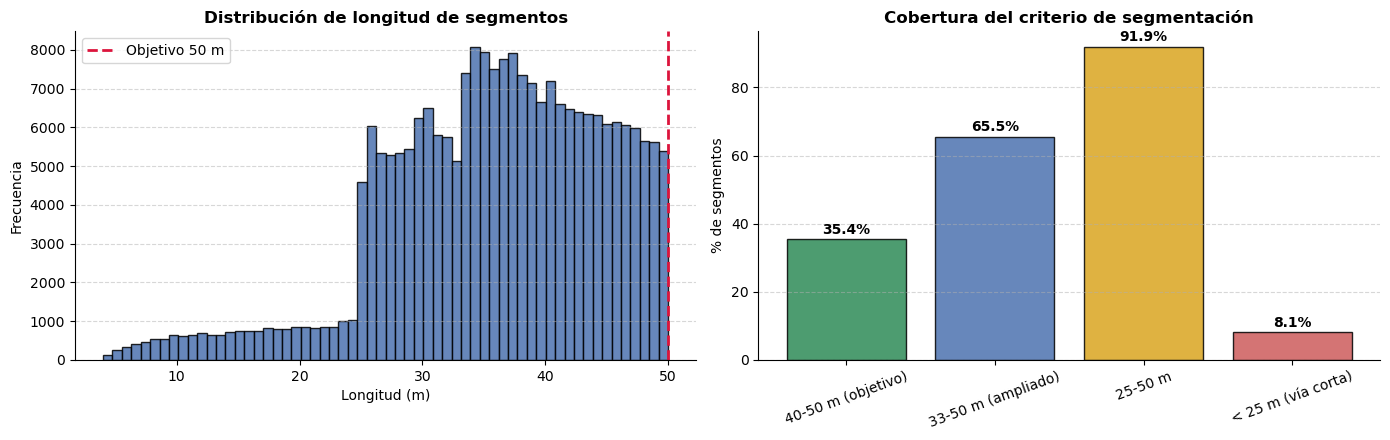

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(segmentos['long_seg_m'], bins=60, color='#4C72B0', edgecolor='black', alpha=0.85)
axes[0].axvline(LONG_OBJETIVO, color='crimson', linestyle='--', linewidth=2,
                label=f'Objetivo {LONG_OBJETIVO} m')
axes[0].set_title('Distribución de longitud de segmentos', fontweight='bold')
axes[0].set_xlabel('Longitud (m)'); axes[0].set_ylabel('Frecuencia')
axes[0].legend(); axes[0].grid(axis='y', linestyle='--', alpha=0.5)

barras = axes[1].bar(resumen_rangos.index, resumen_rangos['pct'],
                     color=['seagreen', '#4C72B0', 'goldenrod', 'indianred'],
                     edgecolor='black', alpha=0.85)
for b, v in zip(barras, resumen_rangos['pct']):
    axes[1].annotate(f'{v:.1f}%', xy=(b.get_x() + b.get_width()/2, v),
                     xytext=(0, 4), textcoords='offset points',
                     ha='center', fontweight='bold')
axes[1].set_title('Cobertura del criterio de segmentación', fontweight='bold')
axes[1].set_ylabel('% de segmentos')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

for ax in axes:
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

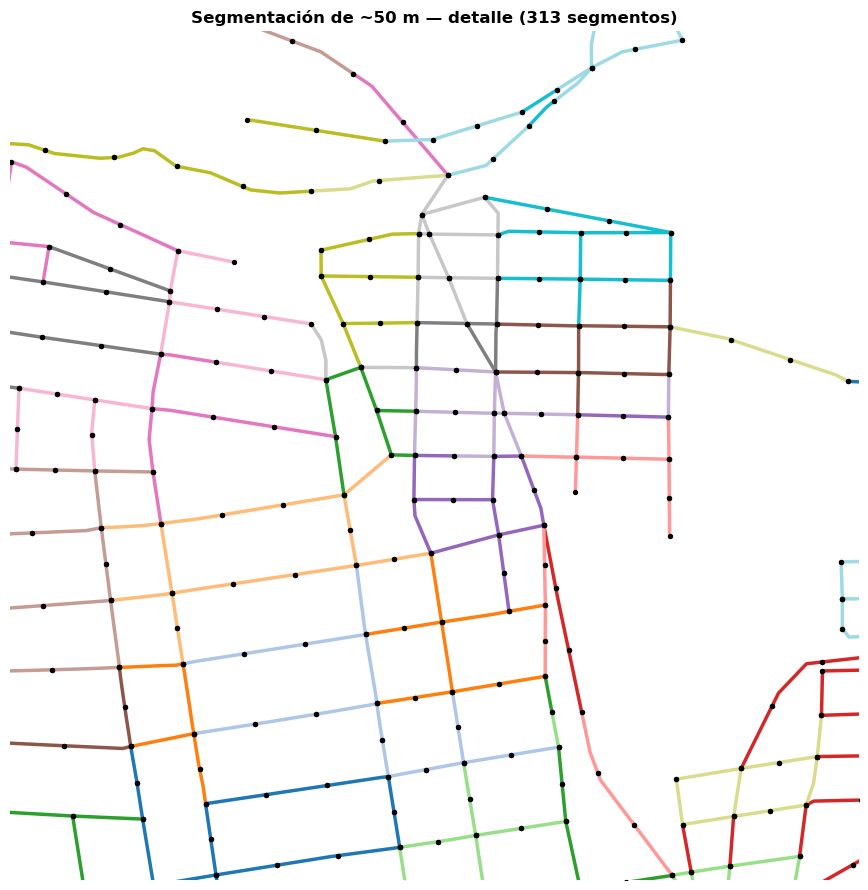

In [ ]:
# Inspección visual de la segmentación en una ventana pequeña: cada tramo en un color
# distinto permite confirmar que los cortes son regulares y siguen la geometría de la vía.
cx, cy = segmentos.geometry.iloc[len(segmentos)//2].centroid.coords[0]
R = 300

ventana = segmentos.cx[cx-R:cx+R, cy-R:cy+R]
fig, ax = plt.subplots(figsize=(9, 9))
ventana.plot(ax=ax, column='seg_id', cmap='tab20', linewidth=2.5, legend=False)
ventana.geometry.boundary.plot(ax=ax, color='black', markersize=8, zorder=3)
ax.set_xlim(cx-R, cx+R); ax.set_ylim(cy-R, cy+R)
ax.set_title(f'Segmentación de ~{LONG_OBJETIVO} m — detalle ({len(ventana)} segmentos)',
             fontweight='bold')
ax.set_axis_off(); plt.tight_layout(); plt.show()

## 4. Zonas de influencia: buffers por segmento

Cada segmento se convierte en un polígono de influencia con `buffer(r)`. Se usa
`cap_style=2` (plano) para que el buffer **no se prolongue más allá de los extremos** del
tramo: con el cap redondeado por defecto, un segmento capturaría infraestructura que está
al frente de los segmentos vecinos, inflando artificialmente la correlación entre tramos
contiguos.

In [ ]:
def construir_buffers(seg, radio):
    """Zona de influencia de cada segmento. cap_style=2 (plano) evita el
    desbordamiento longitudinal hacia los segmentos vecinos."""
    buf = seg[['seg_id', 'long_seg_m']].copy()
    buf['geometry'] = seg.geometry.buffer(radio, cap_style=2)
    return gpd.GeoDataFrame(buf, geometry='geometry', crs=seg.crs)

buffers = {r: construir_buffers(segmentos, r) for r in BUFFERS}

for r, b in buffers.items():
    print(f"Buffer {r:>2} m -> área media por segmento: {b.geometry.area.mean():8.1f} m² | "
          f"área total cubierta (con traslape): {b.geometry.area.sum()/1e6:8.2f} km²")

Buffer 10 m -> área media por segmento:    715.8 m² | área total cubierta (con traslape):   162.99 km²
Buffer 15 m -> área media por segmento:   1073.8 m² | área total cubierta (con traslape):   244.51 km²
Buffer 20 m -> área media por segmento:   1432.0 m² | área total cubierta (con traslape):   326.07 km²


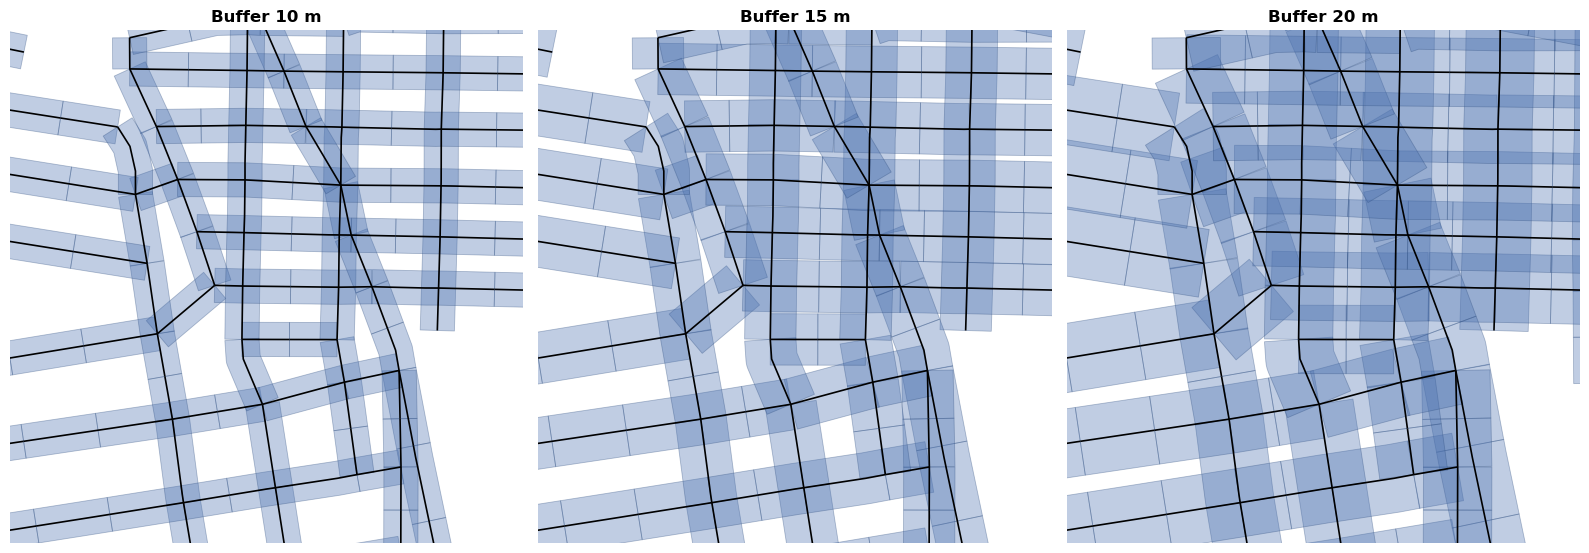

In [ ]:
# Comparación visual de los tres radios sobre la misma ventana
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, r in zip(axes, BUFFERS):
    sub = buffers[r][buffers[r]['seg_id'].isin(ventana['seg_id'])]
    sub.plot(ax=ax, color='#4C72B0', alpha=0.35, edgecolor='#2b4b7d', linewidth=0.6)
    ventana.plot(ax=ax, color='black', linewidth=1.2)
    ax.set_xlim(cx-R/2, cx+R/2); ax.set_ylim(cy-R/2, cy+R/2)
    ax.set_title(f'Buffer {r} m', fontweight='bold'); ax.set_axis_off()
plt.tight_layout(); plt.show()

## 5. Agregación de las capas a cada segmento

### 5.1 Nota metodológica sobre el doble conteo

Con buffers, un mismo elemento (un semáforo, un siniestro) puede caer dentro de la zona de
influencia de **varios** segmentos —típicamente en intersecciones, donde se cruzan cuatro
tramos. Hay dos lecturas válidas y este cuaderno calcula las dos:

- **Modo `exposicion`** (por defecto): el elemento cuenta para *todos* los segmentos cuyo
  buffer lo contiene. Responde "¿qué infraestructura está presente en el entorno de este
  tramo?". La suma de conteos excede el total real, y eso es correcto: es exposición, no
  inventario.
- **Modo `exclusivo`**: cada elemento se asigna **solo** al segmento más cercano de entre los
  que lo capturan. La suma de conteos reproduce el total real. Necesario si vas a modelar
  tasas o hacer cualquier cosa que asuma independencia entre unidades.

Para un modelo de **conteos de siniestros por segmento** con validación cruzada espacial,
`exclusivo` es el que evita inflar la variable respuesta (el conteo); `exposicion` es el
apropiado para las covariables de infraestructura.

In [ ]:
def asignar_a_segmentos(capa, buf, segs, modo='exposicion'):
    """Devuelve un DataFrame largo (una fila por par elemento-segmento) con la
    asignación de cada elemento de `capa` a los segmentos cuyo buffer lo intersecta.

    modo='exposicion' -> conserva todos los pares.
    modo='exclusivo'  -> conserva, por elemento, solo el segmento más cercano.
    """
    capa = capa.reset_index(drop=True).copy()
    capa['_elem_id'] = capa.index

    pares = gpd.sjoin(capa, buf[['seg_id', 'geometry']],
                      how='inner', predicate='intersects')
    pares = pares.drop(columns=['index_right'])

    if modo == 'exclusivo' and len(pares) > 0:
        geom_seg = segs.set_index('seg_id').geometry
        pares['_dist'] = [
            g.distance(geom_seg.loc[s]) for g, s in zip(pares.geometry, pares['seg_id'])
        ]
        pares = (pares.sort_values('_dist')
                      .drop_duplicates('_elem_id', keep='first')
                      .drop(columns='_dist'))

    # El sjoin conserva el índice de la capa izquierda, que queda con etiquetas
    # repetidas (un elemento -> varios segmentos). pd.crosstab falla sobre un índice
    # no único, así que se normaliza aquí y no en cada función de agregación.
    return pares.reset_index(drop=True)

### 5.2 Puentes

Los puentes son polígonos: un mismo puente cruza legítimamente varios segmentos. Se cuenta por
**código único** (`PueCodigo`), no por filas, y se añade el área de puente que efectivamente
cae dentro del buffer —una medida de cuánta estructura hay sobre el tramo, no solo si la hay.

In [ ]:
COL_ID_PUENTE = 'PueCodigo' if 'PueCodigo' in puentes.columns else puentes.columns[0]

def agregar_puentes(radio, modo='exposicion'):
    pares = asignar_a_segmentos(puentes, buffers[radio], segmentos, modo)
    if len(pares) == 0:
        return pd.DataFrame(columns=['seg_id', 'n_puentes'])
    agg = (pares.groupby('seg_id')
                .agg(n_puentes=(COL_ID_PUENTE, 'nunique'))
                .reset_index())
    return agg

puentes_agg = {r: agregar_puentes(r) for r in BUFFERS}
for r in BUFFERS:
    a = puentes_agg[r]
    print(f"Buffer {r:>2} m -> segmentos con puente: {len(a):,} "
          f"({len(a)/len(segmentos)*100:.2f}%) | máx puentes/segmento: "
          f"{a['n_puentes'].max() if len(a) else 0}")

Buffer 10 m -> segmentos con puente: 6,621 (2.91%) | máx puentes/segmento: 6
Buffer 15 m -> segmentos con puente: 7,464 (3.28%) | máx puentes/segmento: 6
Buffer 20 m -> segmentos con puente: 8,021 (3.52%) | máx puentes/segmento: 6


### 5.3 Semáforos

Puntos: conteo directo de semáforos distintos dentro del buffer. Es la variable que más se
beneficia del modo exclusivo, porque las intersecciones semaforizadas son exactamente donde
se cruzan varios segmentos.

In [ ]:
COL_ID_SEM = 'OBJECTID' if 'OBJECTID' in semaforos.columns else semaforos.columns[0]

def agregar_semaforos(radio, modo='exposicion'):
    pares = asignar_a_segmentos(semaforos, buffers[radio], segmentos, modo)
    if len(pares) == 0:
        return pd.DataFrame(columns=['seg_id', 'n_semaforos'])
    return (pares.groupby('seg_id')
                 .agg(n_semaforos=(COL_ID_SEM, 'nunique'))
                 .reset_index())

semaforos_agg = {r: agregar_semaforos(r) for r in BUFFERS}
for r in BUFFERS:
    a = semaforos_agg[r]
    print(f"Buffer {r:>2} m -> segmentos con semáforo: {len(a):,} "
          f"({len(a)/len(segmentos)*100:.2f}%) | total asignaciones: "
          f"{a['n_semaforos'].sum() if len(a) else 0:,} "
          f"(semáforos reales: {semaforos[COL_ID_SEM].nunique():,})")

Buffer 10 m -> segmentos con semáforo: 3,907 (1.72%) | total asignaciones: 3,909 (semáforos reales: 1,733)
Buffer 15 m -> segmentos con semáforo: 4,493 (1.97%) | total asignaciones: 4,495 (semáforos reales: 1,733)
Buffer 20 m -> segmentos con semáforo: 4,814 (2.11%) | total asignaciones: 4,818 (semáforos reales: 1,733)


### 5.4 Malla peatonal

Es una capa de **líneas**, así que un conteo de elementos dice poco (depende de cómo esté
fragmentada la fuente). La variable informativa es la **longitud de infraestructura peatonal
dentro del buffer**, y su versión normalizada: metros de andén por metro de vía. Esa razón es
comparable entre segmentos de distinta longitud, el conteo crudo no.

In [ ]:
def agregar_peatonal(radio, modo='exposicion'):
    buf = buffers[radio]
    pares = asignar_a_segmentos(peatonal, buf, segmentos, modo)
    if len(pares) == 0:
        return pd.DataFrame(columns=['seg_id', 'n_tramos_peatonal', 'long_peatonal_m'])

    # Longitud real de infraestructura peatonal DENTRO del buffer (no la del tramo completo)
    geom_buf = buf.set_index('seg_id').geometry
    pares['_long_dentro'] = [
        g.intersection(geom_buf.loc[s]).length for g, s in zip(pares.geometry, pares['seg_id'])
    ]
    return (pares.groupby('seg_id')
                 .agg(n_tramos_peatonal=('_elem_id', 'nunique'),
                      long_peatonal_m=('_long_dentro', 'sum'))
                 .reset_index())

peatonal_agg = {r: agregar_peatonal(r) for r in BUFFERS}
for r in BUFFERS:
    a = peatonal_agg[r]
    print(f"Buffer {r:>2} m -> segmentos con infra peatonal: {len(a):,} "
          f"({len(a)/len(segmentos)*100:.2f}%) | long. media: "
          f"{a['long_peatonal_m'].mean() if len(a) else 0:.1f} m")

Buffer 10 m -> segmentos con infra peatonal: 109,512 (48.09%) | long. media: 38.5 m
Buffer 15 m -> segmentos con infra peatonal: 110,197 (48.40%) | long. media: 47.6 m
Buffer 20 m -> segmentos con infra peatonal: 111,015 (48.75%) | long. media: 54.4 m


### 5.5 Conteo de siniestros por segmento (variable objetivo)

El **conteo de siniestros peatonales por segmento** es la variable objetivo de este cuaderno, así que se agrega con más detalle que las covariables: conteo total de siniestros, número de peatones afectados, y descriptores de contexto adicionales (desagregación por `ESTADO`, perfil de las víctimas y momento del siniestro) que quedan disponibles como variables descriptivas, no como la definición del objetivo.

Se calcula en modo **exclusivo** además del de exposición, porque para un modelo de conteos la suma de siniestros por segmento debe reproducir el total real de la ciudad.

In [ ]:
print("Columnas disponibles en siniestros:")
print(sorted(siniestros.columns.tolist()))
print()
if 'ESTADO' in siniestros.columns:
    print(siniestros['ESTADO'].value_counts(dropna=False))

Columnas disponibles en siniestros:
['ANO_OCURRENCIA_ACC', 'CAUSA_PRINCIPAL', 'CLASE', 'CODIGO_ACCIDENTADO', 'CODIGO_ACCIDENTE', 'CODIGO_LOCALIDAD', 'CONDICION', 'DIA_SEMANA', 'DIRECCION', 'DISENO_LUGAR', 'DISENO_LUGAR_DESC', 'EDAD', 'ESTADO', 'FECHA', 'FECHA_HORA_ACC', 'FECHA_OCURRENCIA_ACC', 'HORA', 'HORA_DIA', 'LATITUD', 'LOCALIDAD_DESC', 'LONGITUD', 'MES', 'SEXO', 'VEHICULO', 'geometry']

ESTADO
HERIDO    20327
MUERTO     1387
ILESO         2
Name: count, dtype: int64


In [ ]:
def agregar_siniestros(radio, modo='exposicion'):
    pares = asignar_a_segmentos(siniestros, buffers[radio], segmentos, modo)
    if len(pares) == 0:
        return pd.DataFrame(columns=['seg_id', 'n_siniestros'])

    col_acc = 'CODIGO_ACCIDENTE' if 'CODIGO_ACCIDENTE' in pares.columns else '_elem_id'

    agg = {'n_peatones_afectados': ('_elem_id', 'nunique'),
           'n_siniestros': (col_acc, 'nunique')}
    if 'EDAD' in pares.columns:
        agg['edad_media_victima'] = ('EDAD', 'mean')
    if 'HORA_DIA' in pares.columns:
        agg['pct_nocturno'] = ('HORA_DIA', lambda s: ((s >= 19) | (s <= 5)).mean() * 100)

    base = pares.groupby('seg_id').agg(**agg).reset_index()

    # Desagregación por gravedad: una columna por estado del peatón
    if 'ESTADO' in pares.columns:
        piv = (pd.crosstab(pares['seg_id'], pares['ESTADO'])
                 .add_prefix('n_').rename(columns=str.lower).reset_index())
        base = base.merge(piv, on='seg_id', how='left')

    # Año más reciente y rango temporal cubierto en el segmento
    if 'ANO_OCURRENCIA_ACC' in pares.columns:
        años = (pares.groupby('seg_id')['ANO_OCURRENCIA_ACC']
                     .agg(ano_min='min', ano_max='max').reset_index())
        base = base.merge(años, on='seg_id', how='left')

    return base

siniestros_agg = {r: agregar_siniestros(r, modo='exposicion') for r in BUFFERS}
siniestros_agg_excl = {r: agregar_siniestros(r, modo='exclusivo') for r in BUFFERS}

for r in BUFFERS:
    a, e = siniestros_agg[r], siniestros_agg_excl[r]
    print(f"Buffer {r:>2} m | exposición: {len(a):>7,} segmentos con siniestro "
          f"({a['n_peatones_afectados'].sum():>7,} asignaciones) | "
          f"exclusivo: {len(e):>7,} segmentos "
          f"({e['n_peatones_afectados'].sum():>7,} asignaciones)")
print(f"\nPeatones afectados reales (tras clip POT): {len(siniestros):,}")

Buffer 10 m | exposición:  22,105 segmentos con siniestro ( 36,509 asignaciones) | exclusivo:  14,149 segmentos ( 21,220 asignaciones)
Buffer 15 m | exposición:  25,030 segmentos con siniestro ( 43,308 asignaciones) | exclusivo:  14,343 segmentos ( 21,531 asignaciones)
Buffer 20 m | exposición:  27,156 segmentos con siniestro ( 48,972 asignaciones) | exclusivo:  14,403 segmentos ( 21,643 asignaciones)

Peatones afectados reales (tras clip POT): 21,716


### 5.6 Cobertura: ¿qué siniestros no captura ningún buffer?

Diagnóstico crítico. Un siniestro que no cae en ningún buffer queda **fuera del modelo**: o su
geocodificación es imprecisa, o ocurrió en una vía que no está en la Malla Vial Integral. Si
esta fracción es alta con 15 m, es el argumento empírico para subir a 20 m.

   buffer_m  siniestros_capturados  siniestros_huerfanos  pct_cobertura
0        10                  21220                   496          97.72
1        15                  21531                   185          99.15
2        20                  21643                    73          99.66


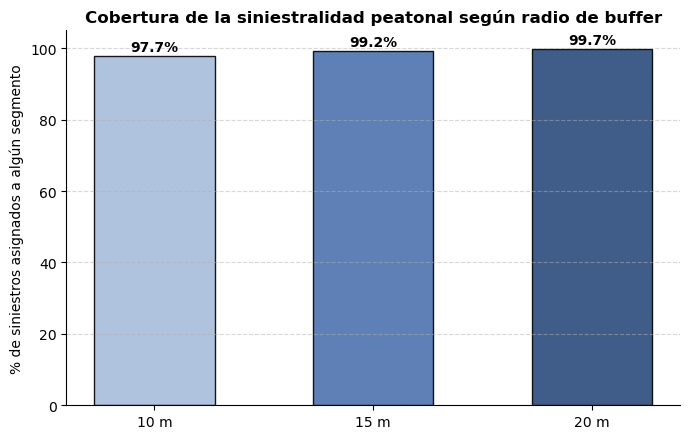

In [ ]:
cobertura = []
for r in BUFFERS:
    asignados = asignar_a_segmentos(siniestros, buffers[r], segmentos,
                                    modo='exclusivo')['_elem_id'].nunique()
    cobertura.append({'buffer_m': r,
                      'siniestros_capturados': asignados,
                      'siniestros_huerfanos': len(siniestros) - asignados,
                      'pct_cobertura': round(asignados / len(siniestros) * 100, 2)})
cobertura = pd.DataFrame(cobertura)
print(cobertura)

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(cobertura['buffer_m'].astype(str) + ' m', cobertura['pct_cobertura'],
                color=['#a6bddb', '#4C72B0', '#2b4b7d'], edgecolor='black', alpha=0.9, width=0.55)
for b, v in zip(barras, cobertura['pct_cobertura']):
    ax.annotate(f'{v:.1f}%', xy=(b.get_x()+b.get_width()/2, v), xytext=(0, 4),
                textcoords='offset points', ha='center', fontweight='bold')
ax.set_title('Cobertura de la siniestralidad peatonal según radio de buffer', fontweight='bold')
ax.set_ylabel('% de siniestros asignados a algún segmento')
ax.set_ylim(0, 105); ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

### 5.7 Integración del anexo de proyecciones de población

Se cruza cada siniestro con la **población proyectada de su localidad en el año en que ocurrió**
(anexo `anexo-proyecciones-poblacion-bogota-...-2018-2035-UPZ-2018-2024.xlsx`, hoja `Localidades`).
Esto permite, más adelante, leer la siniestralidad no solo en conteos absolutos sino **normalizada
por población expuesta** (tasa por 100.000 habitantes), que es la métrica estándar en epidemiología
de siniestros viales — dos localidades con el mismo número de siniestros no tienen el mismo riesgo
si una tiene el triple de habitantes.

La hoja `Localidades` trae, para cada localidad y año, el desglose `Cabecera Municipal` /
`Centros Poblados y Rural Disperso` / `Total`. Se usa la fila `AREA == 'Total'`, que es la
población total de la localidad ese año.

In [ ]:
RUTA_ANEXO_POBLACION = "data/raw/anexo-proyecciones-poblacion-bogota-desagreacion-loc-2018-2035-UPZ-2018-2024.xlsx"

# La hoja trae 11 filas de título/metadatos antes del encabezado real de columnas
poblacion_raw = pd.read_excel(RUTA_ANEXO_POBLACION, sheet_name='Localidades', header=11)
poblacion_raw = poblacion_raw[poblacion_raw['NOM_LOC'].notna() & (poblacion_raw['NOM_LOC'] != 'NOM_LOC')].copy()

poblacion_localidad = (
    poblacion_raw[poblacion_raw['AREA'] == 'Total']
    [['COD_LOC', 'NOM_LOC', 'AÑO', 'TOTAL HOMBRES', 'TOTAL MUJERES', 'TOTAL']]
    .rename(columns={'AÑO': 'anio', 'TOTAL': 'poblacion_total',
                      'TOTAL HOMBRES': 'poblacion_hombres', 'TOTAL MUJERES': 'poblacion_mujeres'})
    .reset_index(drop=True)
)
poblacion_localidad['anio'] = poblacion_localidad['anio'].astype(int)

print(f"Anexo cargado: {len(poblacion_localidad):,} filas | "
      f"{poblacion_localidad['NOM_LOC'].nunique()} localidades | "
      f"años {poblacion_localidad['anio'].min()}–{poblacion_localidad['anio'].max()}")
poblacion_localidad.head()

Anexo cargado: 360 filas | 20 localidades | años 2018–2035


,COD_LOC,NOM_LOC,anio,poblacion_hombres,poblacion_mujeres,poblacion_total
0,1,Usaquén,2018,246937,288756,535693
1,2,Chapinero,2018,74402,82077,156479
2,3,Santa Fe,2018,51631,52354,103985
3,4,San Cristóbal,2018,186898,198616,385514
4,5,Usme,2018,176971,186423,363394


**Normalización de nombres de localidad.** Los nombres de localidad en el anexo (con tildes,
capitalización estándar) casi nunca coinciden carácter a carácter con los de la fuente de
siniestros (típicamente en mayúsculas y sin tildes). Se normalizan ambos lados antes de cruzar.

In [ ]:
import unicodedata

def normalizar_texto(s):
    """Mayúsculas, sin tildes, sin espacios sobrantes — para cruces de texto robustos."""
    if pd.isna(s):
        return s
    s = str(s).strip().upper()
    s = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    return s

poblacion_localidad['loc_norm'] = poblacion_localidad['NOM_LOC'].map(normalizar_texto)

**Detección de las columnas de localidad y año en `siniestros`.** Se prueba una lista de nombres
candidatos en vez de asumir uno fijo, siguiendo el mismo criterio defensivo usado en el resto del
cuaderno (p. ej. `MVICODIGO`/`OBJECTID`). El año ya se usa en la sección 5.5 como `ANO_OCURRENCIA_ACC`;
aquí se reutiliza la misma columna para mantener consistencia.

In [ ]:
CANDIDATOS_LOCALIDAD = ['LOCALIDAD', 'LOCALIDAD_ACC', 'LOCALIDAD_HECHO', 'LOCALIDAD_SIN',
                        'NOMBRE_LOCALIDAD', 'NOM_LOCALIDAD', 'LOC_NOMBRE', 'LOCALIDAD_DESC']
COL_LOCALIDAD_SIN = next((c for c in CANDIDATOS_LOCALIDAD if c in siniestros.columns), None)
COL_ANIO_SIN = 'ANO_OCURRENCIA_ACC' if 'ANO_OCURRENCIA_ACC' in siniestros.columns else None

print("Columna de localidad detectada en siniestros:", COL_LOCALIDAD_SIN)
print("Columna de año detectada en siniestros       :", COL_ANIO_SIN)

if COL_LOCALIDAD_SIN is None or COL_ANIO_SIN is None:
    print("\n  No se detectó automáticamente alguna de las dos columnas necesarias.")
    print("Columnas disponibles en siniestros:", sorted(siniestros.columns.tolist()))
    print("Ajusta CANDIDATOS_LOCALIDAD (o COL_ANIO_SIN) con el nombre real de la columna y vuelve a",
          "correr esta celda antes de continuar con el resto de la sección 5.7.")

Columna de localidad detectada en siniestros: LOCALIDAD_DESC
Columna de año detectada en siniestros       : ANO_OCURRENCIA_ACC


**Cruce siniestro → población de su localidad-año.** Los años del anexo van de 2018 a 2035; un
siniestro con año fuera de ese rango (p. ej. anterior a 2018) se empareja con el límite más cercano
en vez de perderse, y queda documentado como tal.

In [ ]:
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    siniestros['_loc_norm'] = siniestros[COL_LOCALIDAD_SIN].map(normalizar_texto)
    siniestros['_anio_sin'] = pd.to_numeric(siniestros[COL_ANIO_SIN], errors='coerce').astype('Int64')

    anio_min, anio_max = poblacion_localidad['anio'].min(), poblacion_localidad['anio'].max()
    fuera_de_rango = ((siniestros['_anio_sin'] < anio_min) | (siniestros['_anio_sin'] > anio_max)).sum()
    if fuera_de_rango:
        print(f"{fuera_de_rango} siniestros con año fuera de {anio_min}-{anio_max}; "
              f"se emparejan con el límite más cercano del anexo.")
    siniestros['_anio_match'] = siniestros['_anio_sin'].clip(lower=anio_min, upper=anio_max)

    siniestros = siniestros.merge(
        poblacion_localidad[['loc_norm', 'anio', 'poblacion_total', 'poblacion_hombres', 'poblacion_mujeres']],
        left_on=['_loc_norm', '_anio_match'], right_on=['loc_norm', 'anio'], how='left'
    ).drop(columns=['loc_norm', 'anio'])

    pct_match = siniestros['poblacion_total'].notna().mean() * 100
    print(f"\nSiniestros con población de localidad-año emparejada: {pct_match:.1f}% "
          f"({siniestros['poblacion_total'].notna().sum():,} de {len(siniestros):,})")

    sin_match = sorted(siniestros.loc[siniestros['poblacion_total'].isna(), '_loc_norm'].dropna().unique())
    if sin_match:
        print("\nValores de localidad SIN coincidencia en el anexo (revisar ortografía/alcance):")
        print(sin_match)

11929 siniestros con año fuera de 2018-2035; se emparejan con el límite más cercano del anexo.

Siniestros con población de localidad-año emparejada: 100.0% (21,716 de 21,716)


c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
c:\Users\Brayan\.conda\envs\proyecto\Lib\site-packages\geopandas\geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try

**Tasa de siniestralidad por 100.000 habitantes, por localidad y año.** Este es el indicador
normalizado que responde "¿dónde es más riesgoso caminar?", independiente del tamaño poblacional
de cada localidad — a diferencia del conteo crudo, que simplemente favorece a las localidades más
grandes.

In [ ]:
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    resumen_localidad_anio = (
        siniestros.dropna(subset=['poblacion_total'])
                  .groupby(['_loc_norm', '_anio_match'])
                  .agg(n_siniestros=('_anio_sin', 'size'),
                       poblacion_total=('poblacion_total', 'first'))
                  .reset_index()
                  .rename(columns={'_loc_norm': 'localidad', '_anio_match': 'anio'})
    )
    resumen_localidad_anio['siniestros_por_100k_hab'] = (
        resumen_localidad_anio['n_siniestros'] / resumen_localidad_anio['poblacion_total'] * 100_000
    ).round(2)
    resumen_localidad_anio = resumen_localidad_anio.sort_values(['localidad', 'anio']).reset_index(drop=True)

    print(resumen_localidad_anio.shape)
    resumen_localidad_anio.head(15)

(57, 5)


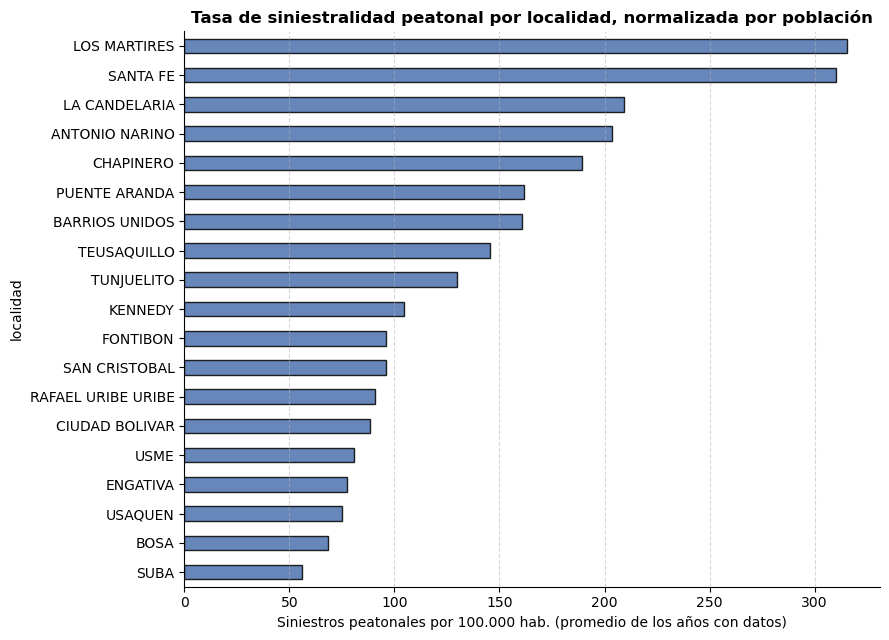

In [ ]:
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    tasa_media_localidad = (resumen_localidad_anio.groupby('localidad')['siniestros_por_100k_hab']
                            .mean().sort_values(ascending=False))

    fig, ax = plt.subplots(figsize=(9, 6.5))
    tasa_media_localidad.plot(kind='barh', ax=ax, color='#4C72B0', edgecolor='black', alpha=0.85)
    ax.invert_yaxis()
    ax.set_xlabel('Siniestros peatonales por 100.000 hab. (promedio de los años con datos)')
    ax.set_title('Tasa de siniestralidad peatonal por localidad, normalizada por población',
                 fontweight='bold')
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    plt.tight_layout(); plt.show()

**Propagación al nivel de segmento.** `agregar_siniestros` se redefine para incluir la población
promedio de la(s) localidad(es)-año representada(s) por los siniestros de cada segmento
(`poblacion_localidad_media`). Se recalculan `siniestros_agg` y `siniestros_agg_excl`, que son los
diccionarios que la sección 6 ya usa para construir el dataset final — no hace falta tocar esa
sección, la nueva columna llega automáticamente al merge.

In [ ]:
def agregar_siniestros(radio, modo='exposicion'):
    pares = asignar_a_segmentos(siniestros, buffers[radio], segmentos, modo)
    if len(pares) == 0:
        return pd.DataFrame(columns=['seg_id', 'n_siniestros'])

    col_acc = 'CODIGO_ACCIDENTE' if 'CODIGO_ACCIDENTE' in pares.columns else '_elem_id'

    agg = {'n_peatones_afectados': ('_elem_id', 'nunique'),
           'n_siniestros': (col_acc, 'nunique')}
    if 'EDAD' in pares.columns:
        agg['edad_media_victima'] = ('EDAD', 'mean')
    if 'HORA_DIA' in pares.columns:
        agg['pct_nocturno'] = ('HORA_DIA', lambda s: ((s >= 19) | (s <= 5)).mean() * 100)
    if 'poblacion_total' in pares.columns:
        agg['poblacion_localidad_media'] = ('poblacion_total', 'mean')

    base = pares.groupby('seg_id').agg(**agg).reset_index()

    # Desagregación por gravedad: una columna por estado del peatón
    if 'ESTADO' in pares.columns:
        piv = (pd.crosstab(pares['seg_id'], pares['ESTADO'])
                 .add_prefix('n_').rename(columns=str.lower).reset_index())
        base = base.merge(piv, on='seg_id', how='left')

    # Año más reciente y rango temporal cubierto en el segmento
    if 'ANO_OCURRENCIA_ACC' in pares.columns:
        años = (pares.groupby('seg_id')['ANO_OCURRENCIA_ACC']
                     .agg(ano_min='min', ano_max='max').reset_index())
        base = base.merge(años, on='seg_id', how='left')

    return base

siniestros_agg = {r: agregar_siniestros(r) for r in BUFFERS}
siniestros_agg_excl = {r: agregar_siniestros(r, modo='exclusivo') for r in BUFFERS}

for r in BUFFERS:
    a, e = siniestros_agg[r], siniestros_agg_excl[r]
    print(f"Buffer {r:>2} m | exposición: {len(a):>7,} segmentos con siniestro "
          f"({a['n_peatones_afectados'].sum():>7,} asignaciones) | "
          f"exclusivo: {len(e):>7,} segmentos "
          f"({e['n_peatones_afectados'].sum():>7,} asignaciones)")
if 'poblacion_localidad_media' in siniestros_agg_excl[BUFFER_PRINCIPAL].columns:
    print(f"\nSegmentos (buffer {BUFFER_PRINCIPAL} m) con población de localidad asociada: "
          f"{siniestros_agg_excl[BUFFER_PRINCIPAL]['poblacion_localidad_media'].notna().sum():,}")

Buffer 10 m | exposición:  22,105 segmentos con siniestro ( 36,509 asignaciones) | exclusivo:  14,149 segmentos ( 21,220 asignaciones)
Buffer 15 m | exposición:  25,030 segmentos con siniestro ( 43,308 asignaciones) | exclusivo:  14,343 segmentos ( 21,531 asignaciones)
Buffer 20 m | exposición:  27,156 segmentos con siniestro ( 48,972 asignaciones) | exclusivo:  14,403 segmentos ( 21,643 asignaciones)

Segmentos (buffer 15 m) con población de localidad asociada: 14,343


## 6. Construcción del dataset final por segmento

Una fila = un tramo de ~50 m. Las covariables de infraestructura usan modo **exposición**
(qué hay en el entorno del tramo) y la variable respuesta —el **conteo de siniestros por
segmento**— usa modo **exclusivo** (cada siniestro cuenta una sola vez).

In [ ]:
def construir_dataset(radio):
    ds = segmentos[['seg_id', 'vial_id', 'orden_en_via', 'long_seg_m', 'geometry'] +
                   [c for c in ['MVITIPO', 'MVISVIA'] if c in segmentos.columns]].copy()

    ds = ds.merge(puentes_agg[radio],   on='seg_id', how='left')
    ds = ds.merge(semaforos_agg[radio], on='seg_id', how='left')
    ds = ds.merge(peatonal_agg[radio],  on='seg_id', how='left')
    ds = ds.merge(siniestros_agg_excl[radio], on='seg_id', how='left')

    # Conteos ausentes = ausencia real del fenómeno, no dato faltante
    cols_conteo = [c for c in ds.columns
                   if c.startswith('n_') or c in ('long_peatonal_m',)]
    ds[cols_conteo] = ds[cols_conteo].fillna(0)
    for c in cols_conteo:
        if ds[c].dropna().mod(1).eq(0).all():
            ds[c] = ds[c].astype(int)

    # Variables derivadas normalizadas por longitud: comparables entre segmentos
    ds['dens_peatonal'] = ds['long_peatonal_m'] / ds['long_seg_m']
    ds['tiene_semaforo'] = ds['n_semaforos'] > 0
    ds['tiene_puente']   = ds['n_puentes'] > 0
    ds['tiene_infra_peatonal'] = ds['long_peatonal_m'] > 0
    if 'n_peatones_afectados' in ds.columns:
        ds['siniestros_por_100m'] = ds['n_peatones_afectados'] / ds['long_seg_m'] * 100
        ds['tuvo_siniestro'] = ds['n_peatones_afectados'] > 0
    ds['buffer_m'] = radio
    return ds

datasets = {r: construir_dataset(r) for r in BUFFERS}
dataset_final = datasets[BUFFER_PRINCIPAL]

print(f"Dataset final (buffer {BUFFER_PRINCIPAL} m): {dataset_final.shape}")
dataset_final.head()

Dataset final (buffer 15 m): (227702, 28)


,seg_id,vial_id,orden_en_via,long_seg_m,geometry,MVITIPO,MVISVIA,n_puentes,n_semaforos,n_tramos_peatonal,long_peatonal_m,n_peatones_afectados,n_siniestros,edad_media_victima,pct_nocturno,poblacion_localidad_media,n_herido,n_ileso,n_muerto,ano_min,ano_max,dens_peatonal,tiene_semaforo,tiene_puente,tiene_infra_peatonal,siniestros_por_100m,tuvo_siniestro,buffer_m
0,S0000000,91428,0,30.958381,"LINESTRING (988757.414 997892.228, 988727.382 ...",CL,SD,0,0,0,0.0,0,0,NaN,NaN,NaN,0,0,0,NaN,NaN,0.0,False,False,False,0.0,False,15
1,S0000001,103844,0,35.729601,"LINESTRING (988786.272 997913.035, 988771.253 ...",CL,SD,0,0,0,0.0,0,0,NaN,NaN,NaN,0,0,0,NaN,NaN,0.0,False,False,False,0.0,False,15
2,S0000002,136273,0,31.900881,"LINESTRING (988935.627 997898.403, 988910.141 ...",DG,SD,0,0,0,0.0,0,0,NaN,NaN,NaN,0,0,0,NaN,NaN,0.0,False,False,False,0.0,False,15
3,S0000003,122955,0,48.556662,"LINESTRING (988745.967 997939.416, 988752.964 ...",KR,SD,0,0,0,0.0,0,0,NaN,NaN,NaN,0,0,0,NaN,NaN,0.0,False,False,False,0.0,False,15
4,S0000004,106448,0,21.075999,"LINESTRING (988910.141 997917.589, 988899.533 ...",DG,SD,0,0,0,0.0,0,0,NaN,NaN,NaN,0,0,0,NaN,NaN,0.0,False,False,False,0.0,False,15


In [ ]:
# Perfil del dataset: qué proporción de segmentos tiene cada característica
perfil = pd.DataFrame({
    r: {
        'segmentos': len(datasets[r]),
        '% con semáforo': datasets[r]['tiene_semaforo'].mean() * 100,
        '% con puente': datasets[r]['tiene_puente'].mean() * 100,
        '% con infra peatonal': datasets[r]['tiene_infra_peatonal'].mean() * 100,
        '% con siniestro': datasets[r]['tuvo_siniestro'].mean() * 100,
        'siniestros totales': datasets[r]['n_peatones_afectados'].sum(),
    } for r in BUFFERS
}).T.round(2)
perfil.index.name = 'buffer_m'
perfil

,segmentos,% con semáforo,% con puente,% con infra peatonal,% con siniestro,siniestros totales
buffer_m,,,,,,
10,227702.0,1.72,2.91,48.09,6.21,21220.0
15,227702.0,1.97,3.28,48.40,6.30,21531.0
20,227702.0,2.11,3.52,48.75,6.33,21643.0


### 6.1 Sensibilidad al radio

Si las tres versiones dan proporciones muy parecidas, el radio no es una decisión crítica y
basta con justificar la elección de 15 m. Si divergen, hay que reportar las tres en el
capítulo de resultados — la conclusión dependería de un parámetro arbitrario.

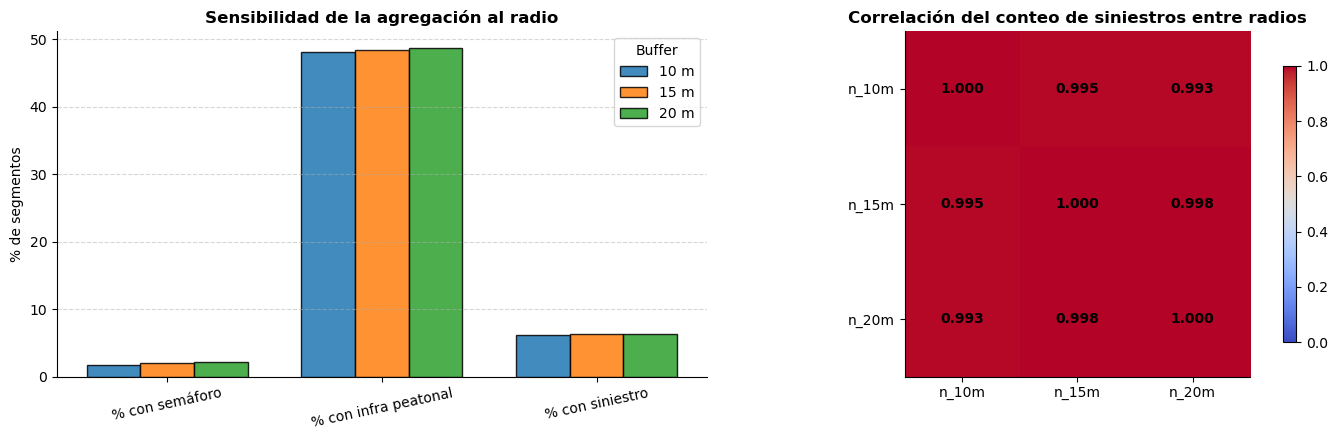

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

indicadores = ['% con semáforo', '% con infra peatonal', '% con siniestro']
x = np.arange(len(indicadores)); ancho = 0.25
for i, r in enumerate(BUFFERS):
    axes[0].bar(x + (i-1)*ancho, perfil.loc[r, indicadores].values, ancho,
                label=f'{r} m', edgecolor='black', alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels(indicadores, rotation=12)
axes[0].set_ylabel('% de segmentos'); axes[0].legend(title='Buffer')
axes[0].set_title('Sensibilidad de la agregación al radio', fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Correlación entre versiones de la variable respuesta
comp = datasets[BUFFERS[0]][['seg_id', 'n_peatones_afectados']].rename(
    columns={'n_peatones_afectados': f'n_{BUFFERS[0]}m'})
for r in BUFFERS[1:]:
    comp = comp.merge(datasets[r][['seg_id', 'n_peatones_afectados']].rename(
        columns={'n_peatones_afectados': f'n_{r}m'}), on='seg_id')
corr = comp.drop(columns='seg_id').corr()
im = axes[1].imshow(corr, cmap='coolwarm', vmin=0, vmax=1)
axes[1].set_xticks(range(len(corr))); axes[1].set_xticklabels(corr.columns)
axes[1].set_yticks(range(len(corr))); axes[1].set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        axes[1].text(j, i, f'{corr.iloc[i,j]:.3f}', ha='center', va='center', fontweight='bold')
axes[1].set_title('Correlación del conteo de siniestros entre radios', fontweight='bold')
plt.colorbar(im, ax=axes[1], shrink=0.8)

for ax in axes:
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

### 6.2 Desbalance de la variable respuesta (conteo de siniestros por segmento)

La mayoría de los ~50 m de vía de Bogotá no tuvo ningún siniestro peatonal. Cuantificarlo aquí
justifica las decisiones de modelado (pesos de clase, métricas distintas de exactitud) y
anticipa si conviene un modelo de conteos inflado en ceros.

Segmentos sin siniestros : 213,359 (93.70%)
Segmentos con ≥1         : 14,343 (6.30%)
Máximo en un segmento    : 46

Distribución de conteos:
n_peatones_afectados
0     213359
1      10365
2       2442
3        831
4        346
5        161
6         70
7         49
8         26
9         13
10        12
11         8
Name: count, dtype: int64


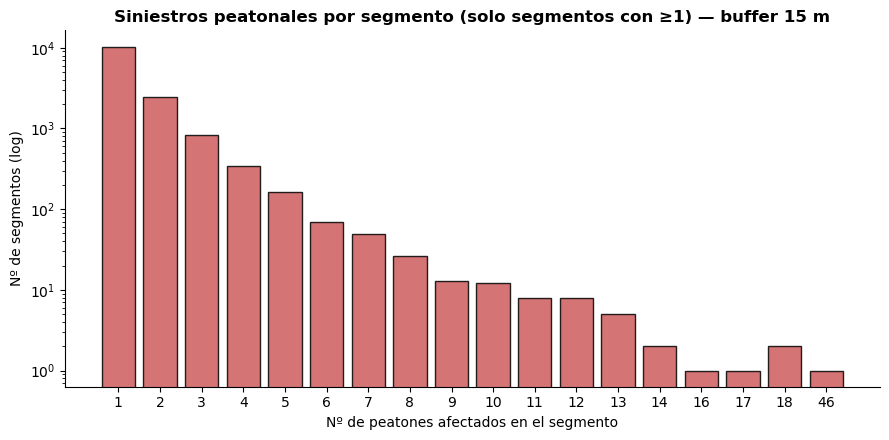

In [ ]:
vr = dataset_final['n_peatones_afectados']
print(f"Segmentos sin siniestros : {(vr == 0).sum():,} ({(vr == 0).mean()*100:.2f}%)")
print(f"Segmentos con ≥1         : {(vr > 0).sum():,} ({(vr > 0).mean()*100:.2f}%)")
print(f"Máximo en un segmento    : {vr.max()}")
print(f"\nDistribución de conteos:")
print(vr.value_counts().sort_index().head(12))

fig, ax = plt.subplots(figsize=(9, 4.5))
conteo_vr = vr[vr > 0].value_counts().sort_index()
ax.bar(conteo_vr.index.astype(str), conteo_vr.values,
       color='indianred', edgecolor='black', alpha=0.85)
ax.set_yscale('log')
ax.set_title(f'Siniestros peatonales por segmento (solo segmentos con ≥1) — buffer {BUFFER_PRINCIPAL} m',
             fontweight='bold')
ax.set_xlabel('Nº de peatones afectados en el segmento'); ax.set_ylabel('Nº de segmentos (log)')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Vista espacial del resultado

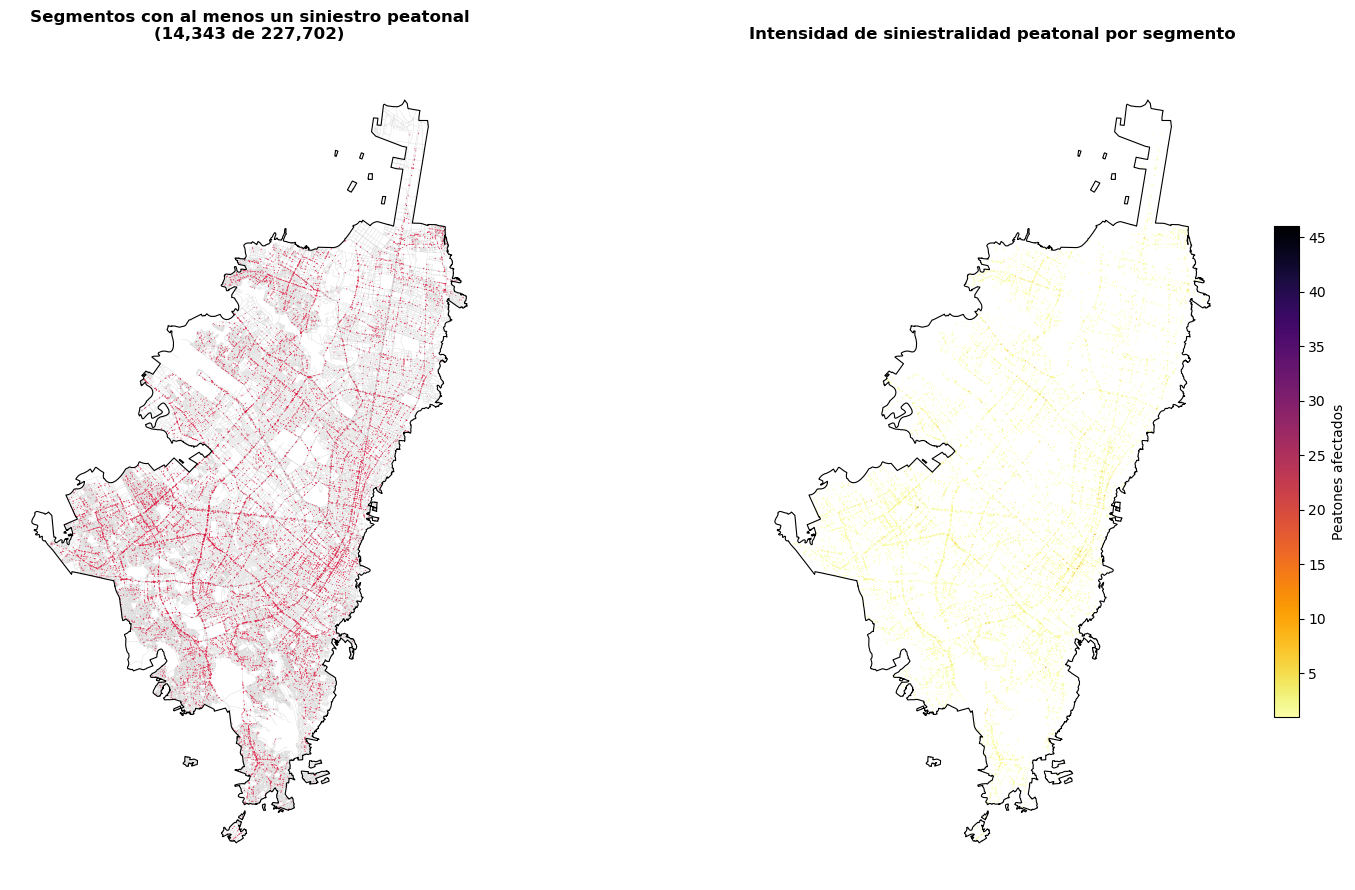

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# Izquierda: red segmentada coloreada por presencia de siniestros
sin_sin = dataset_final[~dataset_final['tuvo_siniestro']]
con_sin = dataset_final[dataset_final['tuvo_siniestro']]
sin_sin.plot(ax=axes[0], color='lightgray', linewidth=0.25, zorder=1)
con_sin.plot(ax=axes[0], color='crimson', linewidth=0.7, zorder=2)
perimetro.boundary.plot(ax=axes[0], color='black', linewidth=0.8, zorder=3)
axes[0].set_title(f'Segmentos con al menos un siniestro peatonal\n'
                  f'({len(con_sin):,} de {len(dataset_final):,})', fontweight='bold')

# Derecha: intensidad
con_sin.plot(ax=axes[1], column='n_peatones_afectados', cmap='inferno_r',
             linewidth=0.9, legend=True, scheme=None,
             legend_kwds={'label': 'Peatones afectados', 'shrink': 0.6})
perimetro.boundary.plot(ax=axes[1], color='black', linewidth=0.8, zorder=3)
axes[1].set_title('Intensidad de siniestralidad peatonal por segmento', fontweight='bold')

for ax in axes:
    ax.set_axis_off()
plt.tight_layout(); plt.show()

## 8. Exportación

Se exporta el dataset principal (buffer de 15 m) como capa de análisis, y las versiones de 10 y
20 m como capas adicionales en el mismo GeoPackage para el análisis de sensibilidad. Se guarda
además la geometría de segmentos sin atributos, que es el esqueleto reutilizable si más adelante
se incorpora otra capa.

In [ ]:
salida = f'{DIR_PROC}/segmentos_50m_unificado.gpkg'

# Capa principal de análisis
dataset_final.to_file(salida, layer=f'segmentos_buffer{BUFFER_PRINCIPAL}m', driver='GPKG')

# Versiones de sensibilidad (radio de buffer)
for r in BUFFERS:
    if r != BUFFER_PRINCIPAL:
        datasets[r].to_file(salida, layer=f'segmentos_buffer{r}m', driver='GPKG')

# Esqueleto de segmentos sin atributos agregados
segmentos[['seg_id', 'vial_id', 'orden_en_via', 'long_seg_m', 'geometry']].to_file(
    salida, layer='segmentos_base', driver='GPKG')

# Versión tabular para modelado (sin geometría)
dataset_final.drop(columns='geometry').to_csv(
    f'{DIR_PROC}/segmentos_50m_buffer{BUFFER_PRINCIPAL}m.csv', index=False)

# Tabla de siniestralidad normalizada por población (anexo de proyecciones), por localidad y año
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    resumen_localidad_anio.to_csv(f'{DIR_PROC}/siniestros_tasa_100k_localidad_anio.csv', index=False)

# Tabla comparativa de granularidad de segmentación (200 / 50 / 25 m)
comparacion_long.to_csv(f'{DIR_PROC}/comparacion_granularidad_segmentos.csv')

print('GeoPackage:', salida)
print('Capas     :', [f'segmentos_buffer{r}m' for r in BUFFERS] + ['segmentos_base'])
print('CSV       :', f'{DIR_PROC}/segmentos_50m_buffer{BUFFER_PRINCIPAL}m.csv')
if COL_LOCALIDAD_SIN and COL_ANIO_SIN:
    print('CSV       :', f'{DIR_PROC}/siniestros_tasa_100k_localidad_anio.csv')
print('CSV       :', f'{DIR_PROC}/comparacion_granularidad_segmentos.csv')
print(f'\nDataset final: {dataset_final.shape[0]:,} segmentos × {dataset_final.shape[1]} columnas')


GeoPackage: Data/processed/segmentos_50m_unificado.gpkg
Capas     : ['segmentos_buffer10m', 'segmentos_buffer15m', 'segmentos_buffer20m', 'segmentos_base']
CSV       : Data/processed/segmentos_50m_buffer15m.csv
CSV       : Data/processed/comparacion_granularidad_segmentos.csv

Dataset final: 227,702 segmentos × 27 columnas


## 9. Comparación de granularidad de segmentación: 200 m, 50 m y 25 m

El cuaderno adoptó **50 m** como longitud de segmento (sección 3). Esta sección cuantifica qué
tanto cambiaría el análisis con tramos más largos (**200 m**, menos ruido, menor resolución
espacial) o más cortos (**25 m**, más resolución, más ceros). El **radio de buffer se deja fijo en
15 m** (`BUFFER_PRINCIPAL`) en las tres corridas, para aislar el efecto del *tamaño del segmento* del
efecto del radio, que ya se analizó por separado en la sección 6.1.

La corrida de 50 m no se repite: se reutiliza `segmentos` / `dataset_final` ya calculados arriba.

In [ ]:
LONGITUDES_COMPARAR = [200, 50, 25]
BUFFER_COMPARACION = BUFFER_PRINCIPAL  # fijo, para aislar el efecto del tamaño de segmento

def pipeline_segmentacion(objetivo):
    """Segmenta la malla a `objetivo` metros, construye buffers a BUFFER_COMPARACION
    y agrega la siniestralidad peatonal (modo exclusivo). Reutiliza las mismas funciones
    ya definidas arriba (segmentar_capa, construir_buffers, asignar_a_segmentos)."""
    segs = segmentar_capa(malla_base, objetivo=objetivo)
    buf = construir_buffers(segs, BUFFER_COMPARACION)
    pares = asignar_a_segmentos(siniestros, buf, segs, modo='exclusivo')

    if len(pares) == 0:
        agg = pd.DataFrame(columns=['seg_id', 'n_peatones_afectados'])
    else:
        agg = (pares.groupby('seg_id').agg(n_peatones_afectados=('_elem_id', 'nunique'))
                    .reset_index())

    ds = segs[['seg_id', 'vial_id', 'long_seg_m']].merge(agg, on='seg_id', how='left')
    ds['n_peatones_afectados'] = ds['n_peatones_afectados'].fillna(0).astype(int)
    ds['tuvo_siniestro'] = ds['n_peatones_afectados'] > 0
    ds['siniestros_por_100m'] = ds['n_peatones_afectados'] / ds['long_seg_m'] * 100
    return segs, ds

resultados_long = {}
for L in LONGITUDES_COMPARAR:
    if L == LONG_OBJETIVO:
        # Ya calculado arriba con el mismo buffer principal: no se repite el cómputo.
        segs = segmentos
        ds = dataset_final[['seg_id', 'vial_id', 'long_seg_m', 'n_peatones_afectados',
                            'tuvo_siniestro', 'siniestros_por_100m']].copy()
    else:
        segs, ds = pipeline_segmentacion(L)
    resultados_long[L] = {'segmentos': segs, 'dataset': ds}
    print(f"{L:>4} m -> {len(ds):>8,} segmentos generados")

 200 m ->  134,133 segmentos generados
  50 m ->  227,702 segmentos generados
  25 m ->  395,116 segmentos generados


### 9.1 Tabla comparativa

In [ ]:
comparacion_long = pd.DataFrame({
    L: {
        'n_segmentos': len(r['dataset']),
        'long_media_m': r['dataset']['long_seg_m'].mean(),
        'long_mediana_m': r['dataset']['long_seg_m'].median(),
        '% con siniestro': r['dataset']['tuvo_siniestro'].mean() * 100,
        'siniestros totales capturados': r['dataset']['n_peatones_afectados'].sum(),
        'siniestros/100m (solo con siniestro)': r['dataset'].loc[
            r['dataset']['tuvo_siniestro'], 'siniestros_por_100m'].mean(),
    } for L, r in resultados_long.items()
}).T.round(2)
comparacion_long.index.name = 'longitud_segmento_m'
comparacion_long = comparacion_long.sort_index(ascending=False)
comparacion_long

,n_segmentos,long_media_m,long_mediana_m,% con siniestro,siniestros totales capturados,siniestros/100m (solo con siniestro)
longitud_segmento_m,,,,,,
200,134133.0,60.76,50.26,9.95,21531.0,3.51
50,227702.0,35.79,36.55,6.30,21531.0,4.79
25,395116.0,20.63,21.40,3.80,21531.0,7.42


El total de "siniestros totales capturados" debe ser prácticamente igual entre las tres filas: al
mantener el mismo radio de buffer y el modo exclusivo, lo que cambia es **cómo se reparte** ese
total entre segmentos, no cuántos siniestros se capturan en conjunto. Pequeñas diferencias vienen
de casos límite en los extremos de segmento (`cap_style=2`).

### 9.2 Distribución de longitud de segmento por granularidad

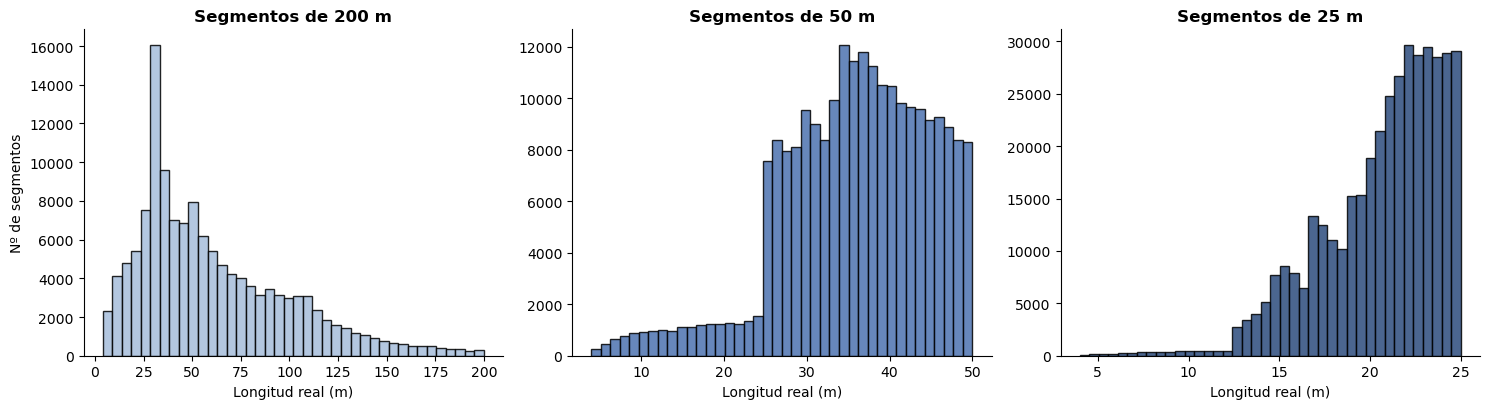

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
colores = {200: '#a6bddb', 50: '#4C72B0', 25: '#2b4b7d'}
for ax, L in zip(axes, LONGITUDES_COMPARAR):
    ax.hist(resultados_long[L]['dataset']['long_seg_m'], bins=40,
            color=colores[L], edgecolor='black', alpha=0.85)
    ax.set_title(f'Segmentos de {L} m', fontweight='bold')
    ax.set_xlabel('Longitud real (m)')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
axes[0].set_ylabel('Nº de segmentos')
plt.tight_layout(); plt.show()

### 9.3 % de segmentos con al menos un siniestro, por granularidad

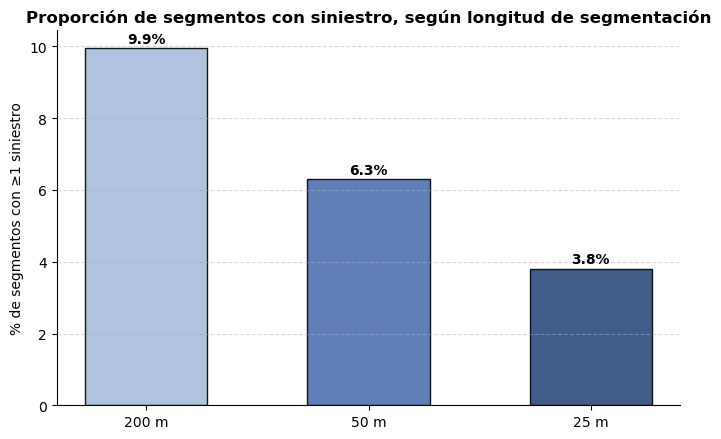

A menor longitud de segmento, la red se fragmenta en más unidades y el mismo número
de siniestros se reparte más delgado: es esperable que el % con siniestro baje al pasar
de 200 m a 25 m, y que la variable respuesta se vuelva más dispersa en ceros.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
valores = [comparacion_long.loc[L, '% con siniestro'] for L in LONGITUDES_COMPARAR]
barras = ax.bar([f'{L} m' for L in LONGITUDES_COMPARAR], valores,
                color=[colores[L] for L in LONGITUDES_COMPARAR], edgecolor='black', alpha=0.9,
                width=0.55)
for b, v in zip(barras, valores):
    ax.annotate(f'{v:.1f}%', xy=(b.get_x() + b.get_width()/2, v), xytext=(0, 4),
                textcoords='offset points', ha='center', fontweight='bold')
ax.set_ylabel('% de segmentos con ≥1 siniestro')
ax.set_title('Proporción de segmentos con siniestro, según longitud de segmentación',
             fontweight='bold')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

print("A menor longitud de segmento, la red se fragmenta en más unidades y el mismo número")
print("de siniestros se reparte más delgado: es esperable que el % con siniestro baje al pasar")
print("de 200 m a 25 m, y que la variable respuesta se vuelva más dispersa en ceros.")

### 9.4 Vista espacial comparada

Misma ventana geográfica que en la sección 3 (`ventana`), para comparar visualmente cómo cambia la
resolución de la unidad de análisis.

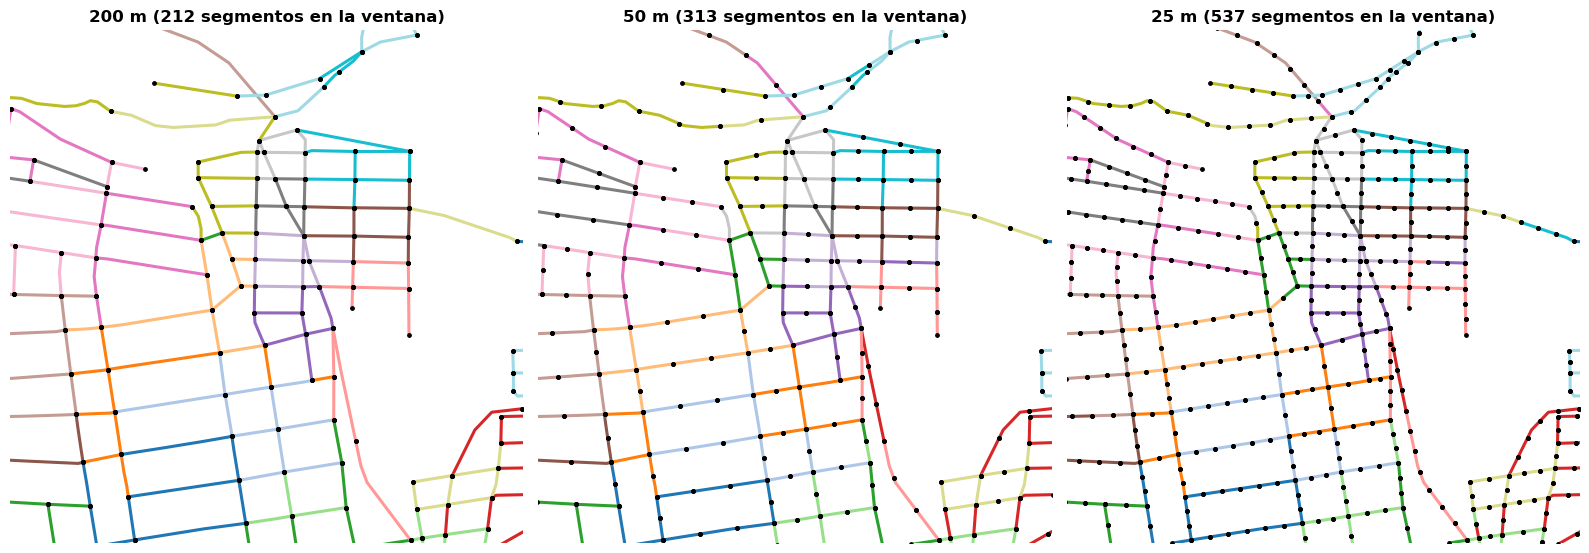

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, L in zip(axes, LONGITUDES_COMPARAR):
    segs_L = resultados_long[L]['segmentos']
    sub = segs_L.cx[cx-R:cx+R, cy-R:cy+R]
    sub.plot(ax=ax, column='seg_id', cmap='tab20', linewidth=2.2, legend=False)
    sub.geometry.boundary.plot(ax=ax, color='black', markersize=6, zorder=3)
    ax.set_xlim(cx-R, cx+R); ax.set_ylim(cy-R, cy+R)
    ax.set_title(f'{L} m ({len(sub)} segmentos en la ventana)', fontweight='bold')
    ax.set_axis_off()
plt.tight_layout(); plt.show()

### 9.5 Correlación del conteo de siniestros entre granularidades

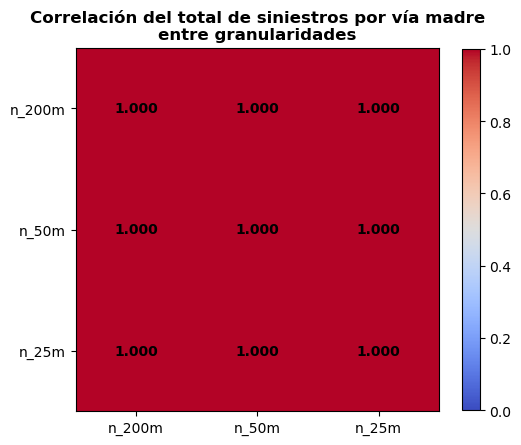

Se agrega por 'vial_id' (la vía completa), no por 'seg_id', porque el id de segmento
no es comparable entre segmentaciones de distinta longitud: una correlación alta aquí
indica que el ORDEN relativo de las vías más peligrosas es estable frente al parámetro
de segmentación, aunque el detalle dentro de cada vía cambie.


In [ ]:
# Comparación agregada por vía madre (vial_id), que es comparable entre granularidades
# distintas -- 'seg_id' no lo es, porque cada longitud produce una segmentación distinta.
comp_vial = None
for L in LONGITUDES_COMPARAR:
    agg_vial = (resultados_long[L]['dataset'].groupby('vial_id')['n_peatones_afectados']
               .sum().rename(f'n_{L}m').reset_index())
    comp_vial = agg_vial if comp_vial is None else comp_vial.merge(agg_vial, on='vial_id', how='outer')
comp_vial = comp_vial.fillna(0)

corr_long = comp_vial.drop(columns='vial_id').corr()
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(corr_long, cmap='coolwarm', vmin=0, vmax=1)
ax.set_xticks(range(len(corr_long))); ax.set_xticklabels(corr_long.columns)
ax.set_yticks(range(len(corr_long))); ax.set_yticklabels(corr_long.columns)
for i in range(len(corr_long)):
    for j in range(len(corr_long)):
        ax.text(j, i, f'{corr_long.iloc[i,j]:.3f}', ha='center', va='center', fontweight='bold')
ax.set_title('Correlación del total de siniestros por vía madre\nentre granularidades',
             fontweight='bold')
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

print("Se agrega por 'vial_id' (la vía completa), no por 'seg_id', porque el id de segmento")
print("no es comparable entre segmentaciones de distinta longitud: una correlación alta aquí")
print("indica que el ORDEN relativo de las vías más peligrosas es estable frente al parámetro")
print("de segmentación, aunque el detalle dentro de cada vía cambie.")

**Lectura de esta sección.** Si `% con siniestro` y la correlación entre granularidades son
razonablemente estables, la elección de 50 m es una decisión de resolución/interpretabilidad y no
cambia las conclusiones sustantivas. Si divergen fuerte, conviene reportar sensibilidad al tamaño de
segmento en los resultados, igual que ya se hace con el radio de buffer en la sección 6.1.

## 10. Resumen metodológico

**Unidad de análisis.** La malla vial recortada al perímetro POT se dividió en tramos de
longitud máxima 50 m mediante división en partes iguales con techo (`n = ceil(L/50)`). Este
criterio elimina las colas residuales del corte a longitud fija y, a diferencia de `round`,
impone 50 m como cota superior dura. La longitud total de red se conserva exactamente
(verificado con una comprobación dura en la sección 3.2).

**Agregación.** Cada segmento define una zona de influencia mediante buffer con extremo plano
(`cap_style=2`), de forma que no captura elementos situados frente a los tramos vecinos. Se
calcularon tres radios (10, 15 y 20 m); 15 m alimenta el dataset principal y los otros dos
quedan como análisis de sensibilidad reportado.

**Doble conteo.** Las covariables de infraestructura se agregan en modo exposición (un elemento
puede contar para varios segmentos: describe el entorno del tramo). La variable respuesta —el **conteo de siniestros por segmento**— se
agrega en modo exclusivo (cada siniestro se asigna únicamente al segmento más cercano), de modo
que la suma por segmento reproduce el total real de siniestros de la ciudad.

**Puntos a revisar con las salidas reales:**
- El % de cobertura de la sección 5.6 decide si 15 m es suficiente o hay que subir a 20 m.
- El % de segmentos en rango 40–50 m (sección 3.3) debería quedar por encima del 90 % con el
  criterio `ceil`. Si queda por debajo de la banda 80–90 % buscada, la causa son vías madre más
  cortas que 50 m —revisa su peso en la red antes de tocar el parámetro.
- El desbalance de la sección 6.2 condiciona la elección de modelo y métricas.

**Integración con proyecciones de población.** Cada siniestro se cruzó con la población proyectada de su localidad en el año de ocurrencia (anexo DANE/SDP 2018-2035), lo que permitió calcular una tasa de siniestralidad por 100.000 habitantes por localidad-año (sección 5.7) y propagar la población representada como atributo contextual a cada segmento (`poblacion_localidad_media`).

**Comparación de granularidad de segmentación.** Además de la sensibilidad al radio de buffer (sección 6.1), se comparó la propia longitud del segmento (200 m, 50 m y 25 m, sección 9), manteniendo el buffer fijo en 15 m. Esto separa el efecto de "cuánto entorno se mira" del efecto de "qué tan fino se corta la vía", y da una base empírica para justificar los 50 m adoptados como unidad de análisis.